**1.Loading Dataset**

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

training = pd.read_csv(
    "twitter_training.csv",
    header=None,
    names=["ID", "Topic", "Sentiment", "Tweet"]
)

validation = pd.read_csv(
    "twitter_validation.csv",
    header=None,
    names=["ID", "Topic", "Sentiment", "Tweet"]
)

print("Training shape:", training.shape)
print("Validation shape:", validation.shape)

training.head()

Training shape: (74682, 4)
Validation shape: (1000, 4)


,ID,Topic,Sentiment,Tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


**2. Inspecting Data**

In [6]:
print("Column information:")
print(training.info())

print("\nMissing values:")
print(training.isnull().sum())

print("\nSentiment counts:")
print(training["Sentiment"].value_counts())

training.head()

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         74682 non-null  int64 
 1   Topic      74682 non-null  object
 2   Sentiment  74682 non-null  object
 3   Tweet      73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB
None

Missing values:
ID             0
Topic          0
Sentiment      0
Tweet        686
dtype: int64

Sentiment counts:
Sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64


,ID,Topic,Sentiment,Tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


**3. Visualize sentiment distribution**


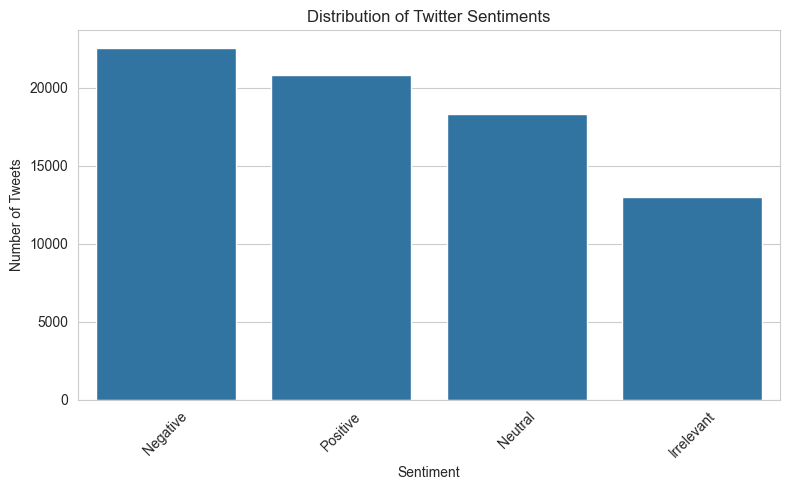

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=training,
    x="Sentiment",
    order=training["Sentiment"].value_counts().index
)

plt.title("Distribution of Twitter Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**4. Cleaning tweet text**

In [19]:
import re

def clean_tweet(text):
    if pd.isna(text):
        return ""
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

training["Clean_Tweet"] = training["Tweet"].apply(clean_tweet)
validation["Clean_Tweet"] = validation["Tweet"].apply(clean_tweet)

training[["Tweet", "Clean_Tweet"]].head()

,Tweet,Clean_Tweet
0,im getting on borderlands and i will murder yo...,im getting on borderlands and i will murder yo...
1,I am coming to the borders and I will kill you...,i am coming to the borders and i will kill you...
2,im getting on borderlands and i will kill you ...,im getting on borderlands and i will kill you all
3,im coming on borderlands and i will murder you...,im coming on borderlands and i will murder you...
4,im getting on borderlands 2 and i will murder ...,im getting on borderlands and i will murder yo...


**5. Removing stopwords**

In [20]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))
stop_words -= {"not", "no", "nor"}

# Recreate cleaned text if the column is missing
if "Clean_Tweet" not in training.columns:
    training["Clean_Tweet"] = training["Tweet"].apply(clean_tweet)

if "Clean_Tweet" not in validation.columns:
    validation["Clean_Tweet"] = validation["Tweet"].apply(clean_tweet)

def remove_stopwords(text):
    return " ".join(
        word for word in text.split()
        if word not in stop_words
    )

training["Clean_Tweet"] = training["Clean_Tweet"].apply(remove_stopwords)
validation["Clean_Tweet"] = validation["Clean_Tweet"].apply(remove_stopwords)

training[["Tweet", "Clean_Tweet"]].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,Tweet,Clean_Tweet
0,im getting on borderlands and i will murder yo...,im getting borderlands murder
1,I am coming to the borders and I will kill you...,coming borders kill
2,im getting on borderlands and i will kill you ...,im getting borderlands kill
3,im coming on borderlands and i will murder you...,im coming borderlands murder
4,im getting on borderlands 2 and i will murder ...,im getting borderlands murder


**6. TF-IDF Vectorization**

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))

X_train = tfidf.fit_transform(training["Clean_Tweet"])
X_val = tfidf.transform(validation["Clean_Tweet"])

y_train = training["Sentiment"]
y_val = validation["Sentiment"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

Training features: (74682, 10000)
Validation features: (1000, 10000)


**7.Train Model 1 — Naive Bayes**

In [14]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

nb_predictions = nb_model.predict(X_val)

print("Naive Bayes Accuracy:",
      round(accuracy_score(y_val, nb_predictions) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_val, nb_predictions, zero_division=0))

Naive Bayes Accuracy: 75.9 %

Classification Report:
              precision    recall  f1-score   support

  Irrelevant       0.83      0.58      0.68       172
    Negative       0.69      0.87      0.77       266
     Neutral       0.85      0.66      0.74       285
    Positive       0.74      0.87      0.80       277

    accuracy                           0.76      1000
   macro avg       0.78      0.74      0.75      1000
weighted avg       0.77      0.76      0.76      1000



**8. Train Model- Logistic Regression**

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

lr_prediction = lr_model.predict(X_val)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_val, lr_prediction) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_val, lr_prediction, zero_division=0))

Logistic Regression Accuracy: 86.5 %

Classification Report:
              precision    recall  f1-score   support

  Irrelevant       0.84      0.77      0.80       172
    Negative       0.84      0.94      0.89       266
     Neutral       0.91      0.82      0.87       285
    Positive       0.86      0.89      0.88       277

    accuracy                           0.86      1000
   macro avg       0.86      0.86      0.86      1000
weighted avg       0.87      0.86      0.86      1000



**9. Confusion matrices**

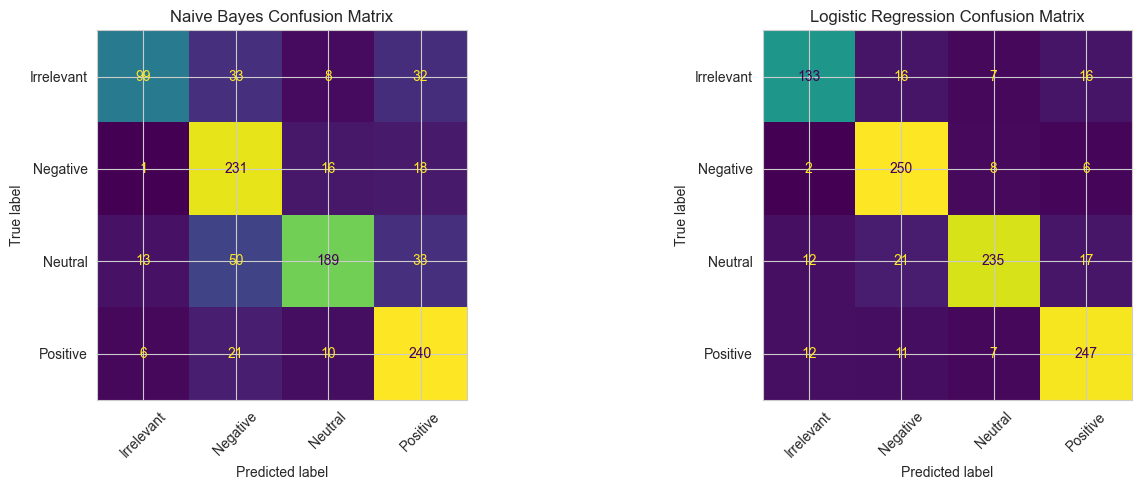

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val, nb_predictions,
    xticks_rotation=45, ax=axes[0], colorbar=False
)
axes[0].set_title("Naive Bayes Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_val, lr_prediction,
    xticks_rotation=45, ax=axes[1], colorbar=False
)
axes[1].set_title("Logistic Regression Confusion Matrix")

plt.tight_layout()
plt.show()

**10. Alternative word-frequency charts**

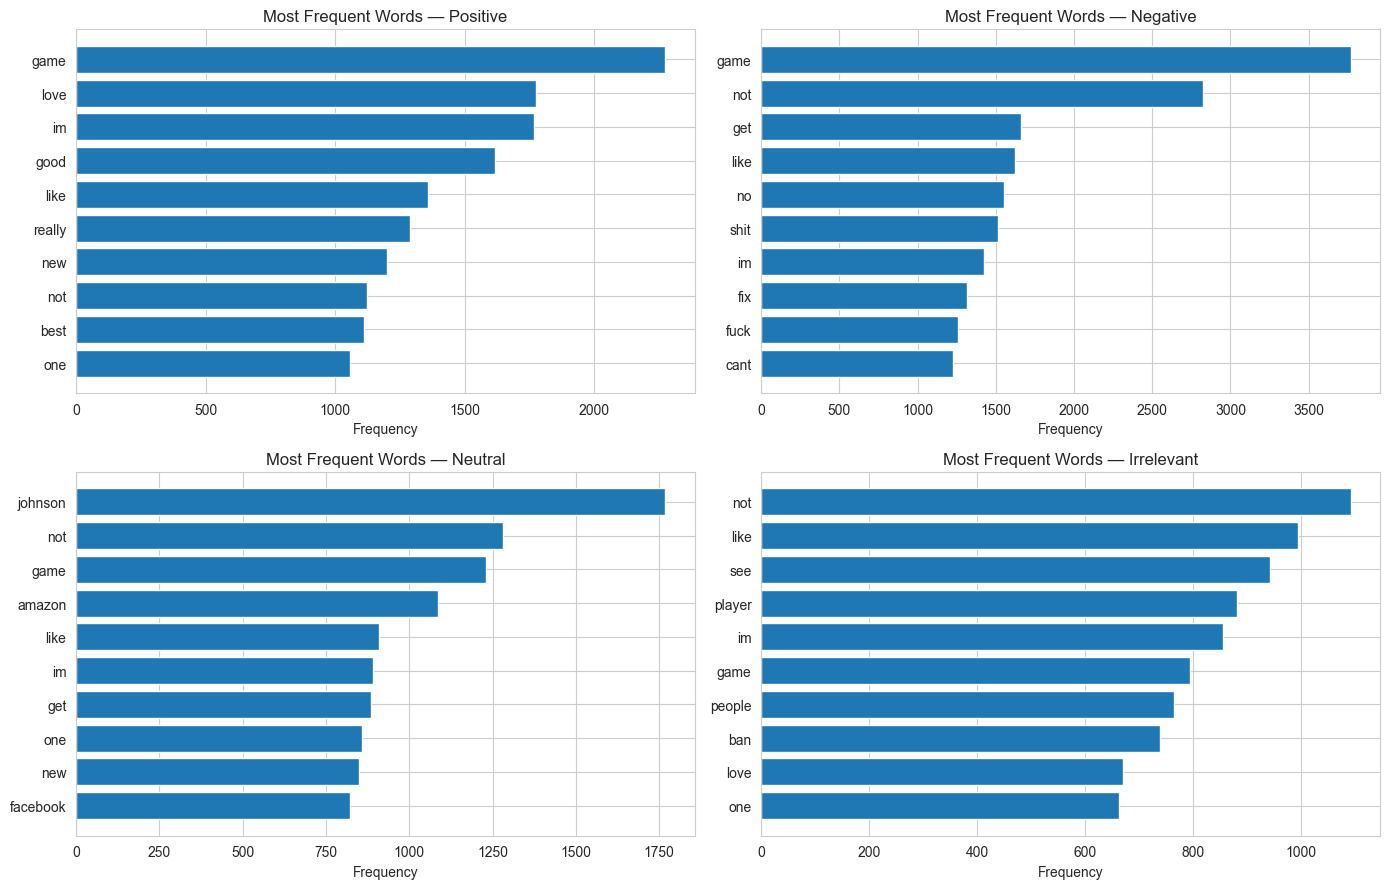

In [18]:
from collections import Counter
import matplotlib.pyplot as plt

sentiments = ["Positive", "Negative", "Neutral", "Irrelevant"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for sentiment, ax in zip(sentiments, axes.flatten()):
    text = " ".join(
        training.loc[
            training["Sentiment"] == sentiment, "Clean_Tweet"
        ].dropna()
    )

    counts = Counter(text.split()).most_common(10)
    words, frequencies = zip(*counts)

    ax.barh(words[::-1], frequencies[::-1])
    ax.set_title(f"Most Frequent Words — {sentiment}")
    ax.set_xlabel("Frequency")

plt.tight_layout()
plt.show()

**11. Finding 5 misclassified tweets**

In [26]:
error_analysis = validation.copy()

error_analysis["Actual"] = y_val.values
error_analysis["Predicted"] = lr_prediction

misclassified = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
]

misclassified[
    ["Tweet", "Actual", "Predicted"]
].head(5)

,Tweet,Actual,Predicted
7,"Rocket League, Sea of Thieves or Rainbow Six: ...",Positive,Irrelevant
10,The professional dota 2 scene is fucking explo...,Positive,Negative
11,Itching to assassinate \n\n#TCCGif #AssassinsC...,Positive,Irrelevant
25,"#gtc20 - nice, motivational, and very accessi...",Neutral,Positive
27,They might not be the last team that has to ma...,Irrelevant,Negative


### **Error Analysis**
The Logistic Regression model misclassified some tweets because social media text can contain slang, abbreviations, sarcasm, spelling mistakes, and ambiguous expressions. Some tweets may also have very little context, making their sentiment difficult to identify. These factors can cause the model to predict a different sentiment from the actual label.

The five misclassified examples illustrate areas where sentiment classification can be improved.

### **Conclusion**

In this project, Twitter posts were classified into Positive, Negative, Neutral, and Irrelevant sentiment classes using NLP techniques and machine learning.

First, the tweets were preprocessed and represented by numerical features with the use of TF-IDF. Two methods for classifying Twitter sentiments were tested – Multinomial Naive Bayes and Logistic Regression.

Multinomial Naive Bayes was able to predict sentiments with **75.9% accuracy** whereas Logistic Regression with **86.5% accuracy** on the test data set.

Sentiment analysis may be useful in business to know the opinions of customers and public feedback on products/services offered.

A drawback of this project is that sarcasm and ambiguous wording may cause misclassification.